
# Preparación de datos y particiones reproducibles

Las particiones se construirán utilizando exclusivamente las imágenes normales del entrenamiento oficial de MVTec AD, manteniendo intacto el conjunto de prueba

## Verificación previa

El análisis exploratorio confirmó:

- 15 categorías disponibles.
- 5.354 imágenes.
- 3.629 imágenes normales de entrenamiento.
- 1.725 imágenes de prueba.
- 1.258 imágenes defectuosas con máscaras válidas.
- 0 archivos duplicados exactos mediante SHA-256.
- 0 coincidencias SHA-256 entre entrenamiento y prueba.

## Protocolo de partición
- Entrenamiento: 80 % de las imágenes normales de cada categoría  
- Validación: 20 % de las imágenes normales de cada categoría  
- Semilla aleatoria: 1926  
- Prueba: conjunto oficial de MVTec AD, sin modificaciones 

Las mismas particiones se utilizarán para Autoencoder CNN, PatchCore con ResNet18 y doble U-Net


Se adoptó una partición de 80 % para entrenamiento y 20 % para validación por categoría, buscando equilibrar la disponibilidad de imágenes normales para el aprendizaje con la necesidad de contar con observaciones independientes para validar los modelos 

Esta decisión es porque algunas categorías de MVTec AD disponen de pocos ejemplos de entrenamiento. Una proporción de validación mayor reduciría los ejemplos disponibles para representar la variabilidad normal de cada categoría

## Preparación del ambiente

In [5]:

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "requirements.txt").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SPLITS_DIR = PROJECT_ROOT / "results" / "splits"

df_splits = pd.read_csv(SPLITS_DIR / "summary.csv")

display(df_splits)

print("Entrenamiento:", df_splits["train"].sum())
print("Validación:", df_splits["validation"].sum())
print("Total:", df_splits["total"].sum())

,category,train,validation,total,validation_percentage
0,bottle,167,42,209,20.095694
1,cable,179,45,224,20.089286
2,capsule,175,44,219,20.091324
3,carpet,224,56,280,20.000000
4,grid,211,53,264,20.075758
5,hazelnut,313,78,391,19.948849
6,leather,196,49,245,20.000000
7,metal_nut,176,44,220,20.000000
8,pill,214,53,267,19.850187
9,screw,256,64,320,20.000000


Entrenamiento: 2903
Validación: 726
Total: 3629



## Distribución obtenida

Se analizan las particiones generadas por el script de preparación utilizando el archivo `results/splits/summary.csv`

El propósito es comprobar la distribución de imágenes por categoría y verificar que se haya conservado la totalidad de las observaciones normales disponibles


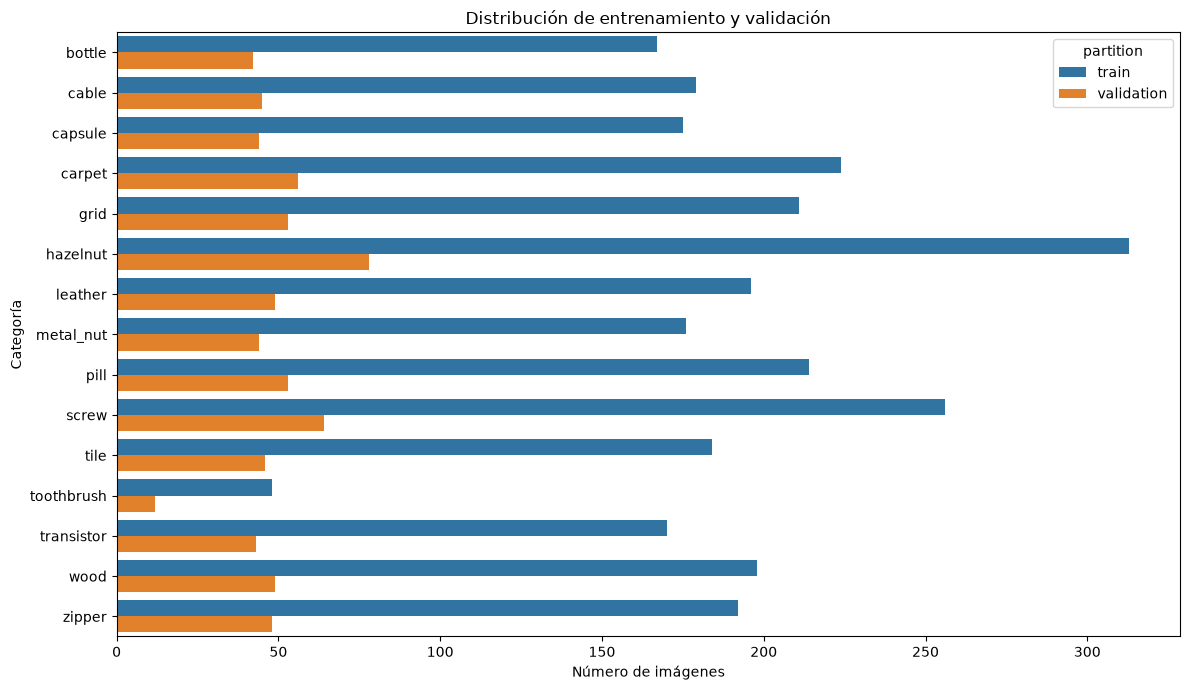

In [3]:

df_plot = df_splits.melt(
    id_vars="category",
    value_vars=["train", "validation"],
    var_name="partition",
    value_name="images"
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=df_plot,
    x="images",
    y="category",
    hue="partition"
)

plt.title("Distribución de entrenamiento y validación")
plt.xlabel("Número de imágenes")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()



## Verificación de integridad

Se comprueba que:

1. Existan imágenes para las 15 categorías
2. Las 3.629 imágenes normales estén asignadas a una única partición
3. No existan solapamientos entre entrenamiento y validación
4. Todas las rutas apunten al entrenamiento oficial y correspondan a archivos existentes

In [ ]:
DATA_DIR = PROJECT_ROOT / "data" / "mvtec_anomaly_detection"

assert len(df_splits) == 15
assert df_splits["total"].sum() == 3629

all_train = set()
all_validation = set()

for category in df_splits["category"]:
    manifest = json.loads((SPLITS_DIR / f"{category}.json").read_text())

    train = set(manifest["train"])
    validation = set(manifest["validation"])

    assert manifest["seed"] == 1926
    assert train.isdisjoint(validation)

    for path in train | validation:
        assert path.startswith(f"{category}/train/good/")
        assert (DATA_DIR / path).is_file(), path

    all_train.update(train)
    all_validation.update(validation)

assert all_train.isdisjoint(all_validation)
assert len(all_train | all_validation) == 3629

print("Categorías:", len(df_splits))
print("Train:", len(all_train))
print("Validación:", len(all_validation))
print("Solapamientos:", len(all_train & all_validation))
print("Integridad: OK")


Categorías: 15
Train: 2903
Validación: 726
Solapamientos: 0
Integridad: OK



## Conclusiones

Se generaron particiones reproducibles para las 15 categorías de MVTec AD utilizando una proporción de 80 % para entrenamiento y 20 % para validación, con semilla 1926

Las diferencias en el número de imágenes por categoría se mantienen, sin realizar submuestreo ni modificar la distribución original

Los manifiestos JSON permiten que Autoencoder CNN, PatchCore y doble U-Net utilicen exactamente las mismas particiones